# 🛡️ Sistema Inteligente de Detección de Transacciones Fraudulentas
## Trabajo Final — Minería de Datos

**Universidad Cooperativa de Colombia — Campus Pasto**
**Docente:** PhD. Cristian Camilo Ordoñez Quintero

**Integrantes:**
- Cristian Gomes
- Ricardo Arias
- Mateo Guerrero
- Kevin Agreda

---

### Objetivo general
Desarrollar un sistema inteligente para detectar transacciones fraudulentas con tarjeta de crédito usando técnicas avanzadas de *machine learning* y aprendizaje profundo sobre el dataset **Credit Card Fraud Detection** ([Kaggle — mlg-ulb/creditcardfraud](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)).

### Requerimientos técnicos que cubre este cuaderno
| Requerimiento | Dónde se cumple |
|---|---|
| Balanceo de clases (**SMOTE**) | Parte 4 |
| **Random Forest** | Parte 5 |
| **XGBoost** (Boosting) | Parte 5 |
| Aprendizaje profundo (**Red Neuronal MLP**) — valor agregado | Parte 5 |
| Métricas: **Precision, Recall, F1, ROC-AUC, matriz de confusión** | Partes 6 y 7 |
| Despliegue web (dashboard, alertas en tiempo real, transacciones sospechosas) | Carpeta `05_Aplicacion_Web` |

### Metodología (CRISP-DM)
1. Comprensión del negocio y de los datos → 2. Exploración (EDA) → 3. Preprocesamiento → 4. Balanceo con SMOTE → 5. Modelado → 6. Evaluación → 7. Optimización del umbral → 8. Interpretación → 9. Validación cruzada → 10. Exportación para el despliegue.

## Parte 0 — Librerías y configuración

In [1]:
import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score,
                             classification_report, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_validate,
                                     train_test_split)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

# Rutas del proyecto (el cuaderno se ejecuta desde 02_Notebook_Analisis)
RUTA_DATOS = Path("../01_Datos/creditcard.csv")
RUTA_MODELOS = Path("../03_Modelos_Entrenados")
RUTA_GRAFICOS = Path("../04_Graficos_Resultados")
RUTA_MODELOS.mkdir(exist_ok=True)
RUTA_GRAFICOS.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
COLOR_NORMAL, COLOR_FRAUDE = "#2E86AB", "#D62828"


def guardar(fig, nombre):
    # Guarda cada gráfico en la carpeta 04_Graficos_Resultados
    fig.savefig(RUTA_GRAFICOS / nombre, bbox_inches="tight", dpi=150)


print("Librerías cargadas correctamente ✔")

Librerías cargadas correctamente ✔


## Parte 1 — Carga y comprensión de los datos

El dataset contiene transacciones realizadas con tarjetas de crédito europeas en **septiembre de 2013**, durante **dos días**.

| Variable | Descripción |
|---|---|
| `Time` | Segundos transcurridos desde la primera transacción del dataset |
| `V1` … `V28` | Componentes principales obtenidos con **PCA** (las variables originales se anonimizaron por confidencialidad) |
| `Amount` | Monto de la transacción (euros) |
| `Class` | Variable objetivo: **1 = fraude**, **0 = transacción legítima** |

In [2]:
df = pd.read_csv(RUTA_DATOS)
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()

Filas: 284,807 | Columnas: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print("Valores nulos totales:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
print("\nTipos de datos:")
print(df.dtypes.value_counts())
df[["Time", "Amount", "Class"]].describe().round(2)

Valores nulos totales: 0


Filas duplicadas: 1081

Tipos de datos:
float64    30
int64       1
Name: count, dtype: int64


,Time,Amount,Class
count,284807.00,284807.00,284807.00
mean,94813.86,88.35,0.00
std,47488.15,250.12,0.04
min,0.00,0.00,0.00
25%,54201.50,5.60,0.00
50%,84692.00,22.00,0.00
75%,139320.50,77.16,0.00
max,172792.00,25691.16,1.00


## Parte 2 — Análisis exploratorio de datos (EDA)
### 2.1 Distribución de la variable objetivo

,Transacciones,Porcentaje (%)
Legítima (0),284315,99.8273
Fraude (1),492,0.1727


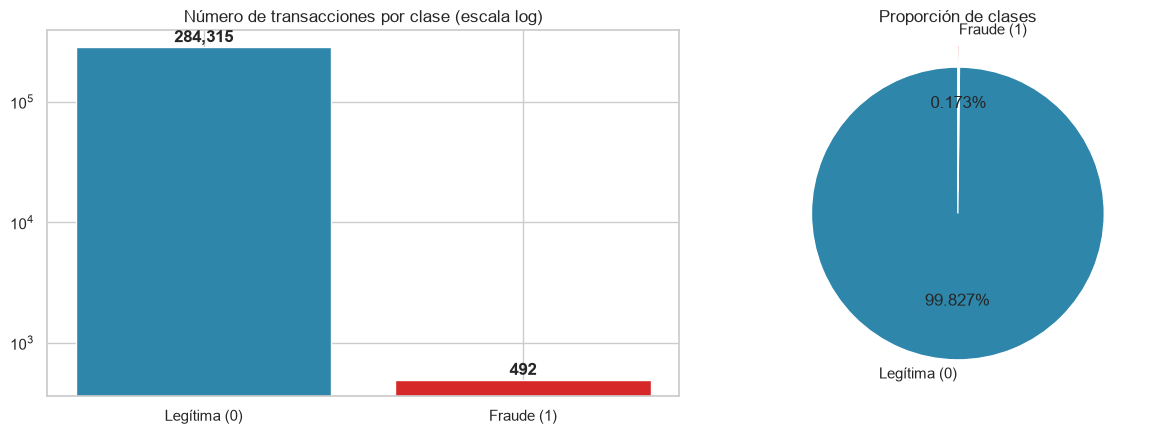

In [4]:
conteo = df["Class"].value_counts().sort_index()
porcentaje = df["Class"].value_counts(normalize=True).sort_index() * 100
resumen_clases = pd.DataFrame({"Transacciones": conteo, "Porcentaje (%)": porcentaje.round(4)})
resumen_clases.index = ["Legítima (0)", "Fraude (1)"]
display(resumen_clases)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
barras = ejes[0].bar(resumen_clases.index, conteo.values, color=[COLOR_NORMAL, COLOR_FRAUDE])
ejes[0].set_yscale("log")
ejes[0].set_title("Número de transacciones por clase (escala log)")
for b, v in zip(barras, conteo.values):
    ejes[0].text(b.get_x() + b.get_width() / 2, v * 1.1, f"{v:,}", ha="center", fontweight="bold")
ejes[1].pie(conteo.values, labels=resumen_clases.index, autopct="%1.3f%%",
            colors=[COLOR_NORMAL, COLOR_FRAUDE], startangle=90, explode=(0, 0.15))
ejes[1].set_title("Proporción de clases")
plt.tight_layout(); guardar(fig, "01_distribucion_clases.png"); plt.show()

### 2.2 Monto de las transacciones (`Amount`) por clase

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
Legítima,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
Fraude,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


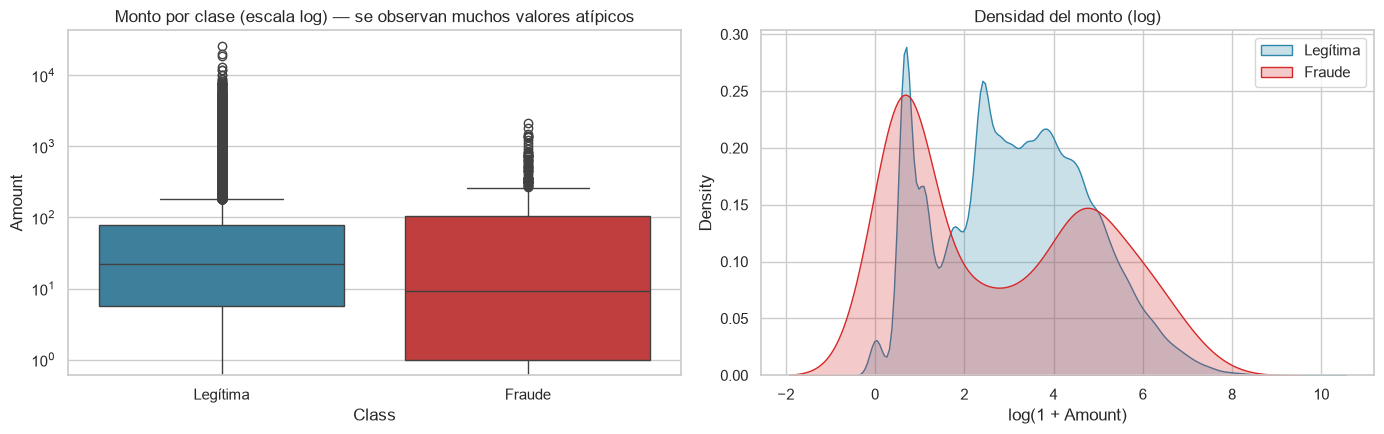

In [5]:
display(df.groupby("Class")["Amount"].describe().rename(index={0: "Legítima", 1: "Fraude"}).round(2))

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x="Class", y="Amount", ax=ejes[0], palette=[COLOR_NORMAL, COLOR_FRAUDE])
ejes[0].set_yscale("log"); ejes[0].set_xticklabels(["Legítima", "Fraude"])
ejes[0].set_title("Monto por clase (escala log) — se observan muchos valores atípicos")
for clase, color, etiqueta in [(0, COLOR_NORMAL, "Legítima"), (1, COLOR_FRAUDE, "Fraude")]:
    sns.kdeplot(np.log1p(df.loc[df["Class"] == clase, "Amount"]), ax=ejes[1],
                fill=True, color=color, label=etiqueta, common_norm=False)
ejes[1].set_xlabel("log(1 + Amount)"); ejes[1].set_title("Densidad del monto (log)"); ejes[1].legend()
plt.tight_layout(); guardar(fig, "02_monto_por_clase.png"); plt.show()

### 2.3 Comportamiento en el tiempo (hora del día)
`Time` está en segundos desde el inicio de la captura (≈ 48 horas). Lo convertimos a **hora del día** (0–23) para ver patrones horarios.

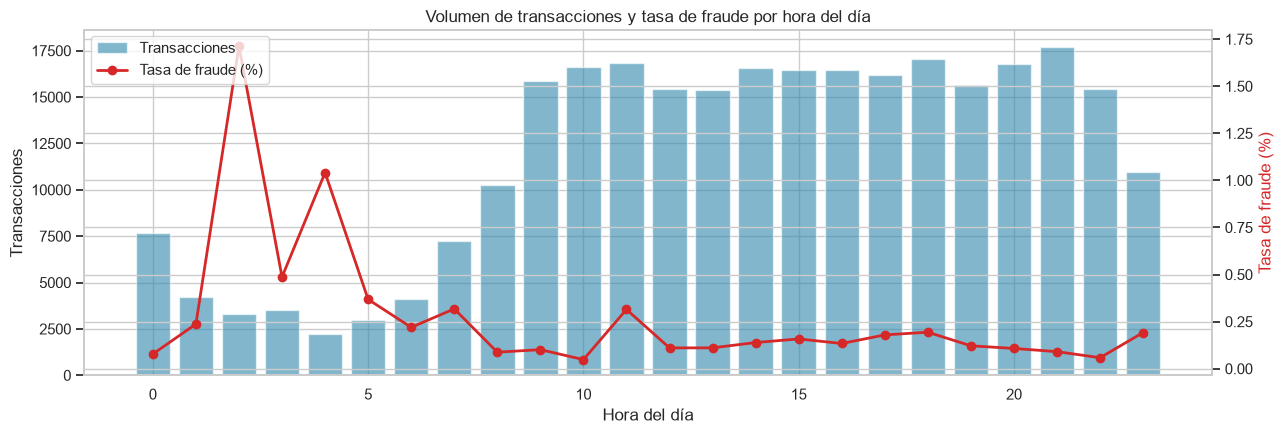

,transacciones,fraudes,tasa_fraude_%
Hora,,,
2.0,3328,57,1.713
4.0,2209,23,1.041
3.0,3492,17,0.487
5.0,2990,11,0.368
7.0,7243,23,0.318


In [6]:
df["Hora"] = (df["Time"] // 3600) % 24
por_hora = df.groupby("Hora").agg(transacciones=("Class", "size"), fraudes=("Class", "sum"))
por_hora["tasa_fraude_%"] = por_hora["fraudes"] / por_hora["transacciones"] * 100

fig, eje1 = plt.subplots(figsize=(13, 4.5))
eje1.bar(por_hora.index, por_hora["transacciones"], color=COLOR_NORMAL, alpha=0.6, label="Transacciones")
eje1.set_xlabel("Hora del día"); eje1.set_ylabel("Transacciones")
eje2 = eje1.twinx()
eje2.plot(por_hora.index, por_hora["tasa_fraude_%"], color=COLOR_FRAUDE, marker="o", lw=2, label="Tasa de fraude (%)")
eje2.set_ylabel("Tasa de fraude (%)", color=COLOR_FRAUDE)
eje1.set_title("Volumen de transacciones y tasa de fraude por hora del día")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.92))
plt.tight_layout(); guardar(fig, "03_fraude_por_hora.png"); plt.show()
por_hora.sort_values("tasa_fraude_%", ascending=False).head(5).round(3)

### 2.4 ¿Qué variables separan mejor el fraude?

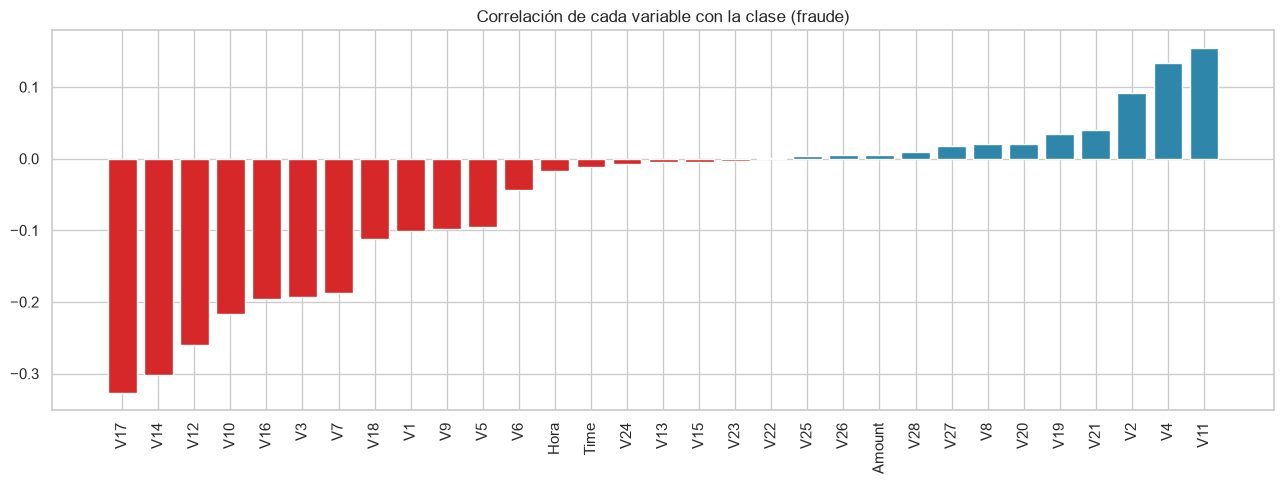

Variables más correlacionadas con el fraude: ['V17', 'V14', 'V12', 'V10', 'V16', 'V3']


In [7]:
corr_clase = df.drop(columns=["Class"]).corrwith(df["Class"]).sort_values()
fig, eje = plt.subplots(figsize=(13, 5))
colores = [COLOR_FRAUDE if v < 0 else COLOR_NORMAL for v in corr_clase.values]
eje.bar(corr_clase.index, corr_clase.values, color=colores)
eje.set_title("Correlación de cada variable con la clase (fraude)")
eje.tick_params(axis="x", rotation=90)
plt.tight_layout(); guardar(fig, "04_correlacion_con_clase.png"); plt.show()

top_variables = corr_clase.abs().sort_values(ascending=False).head(6).index.tolist()
print("Variables más correlacionadas con el fraude:", top_variables)

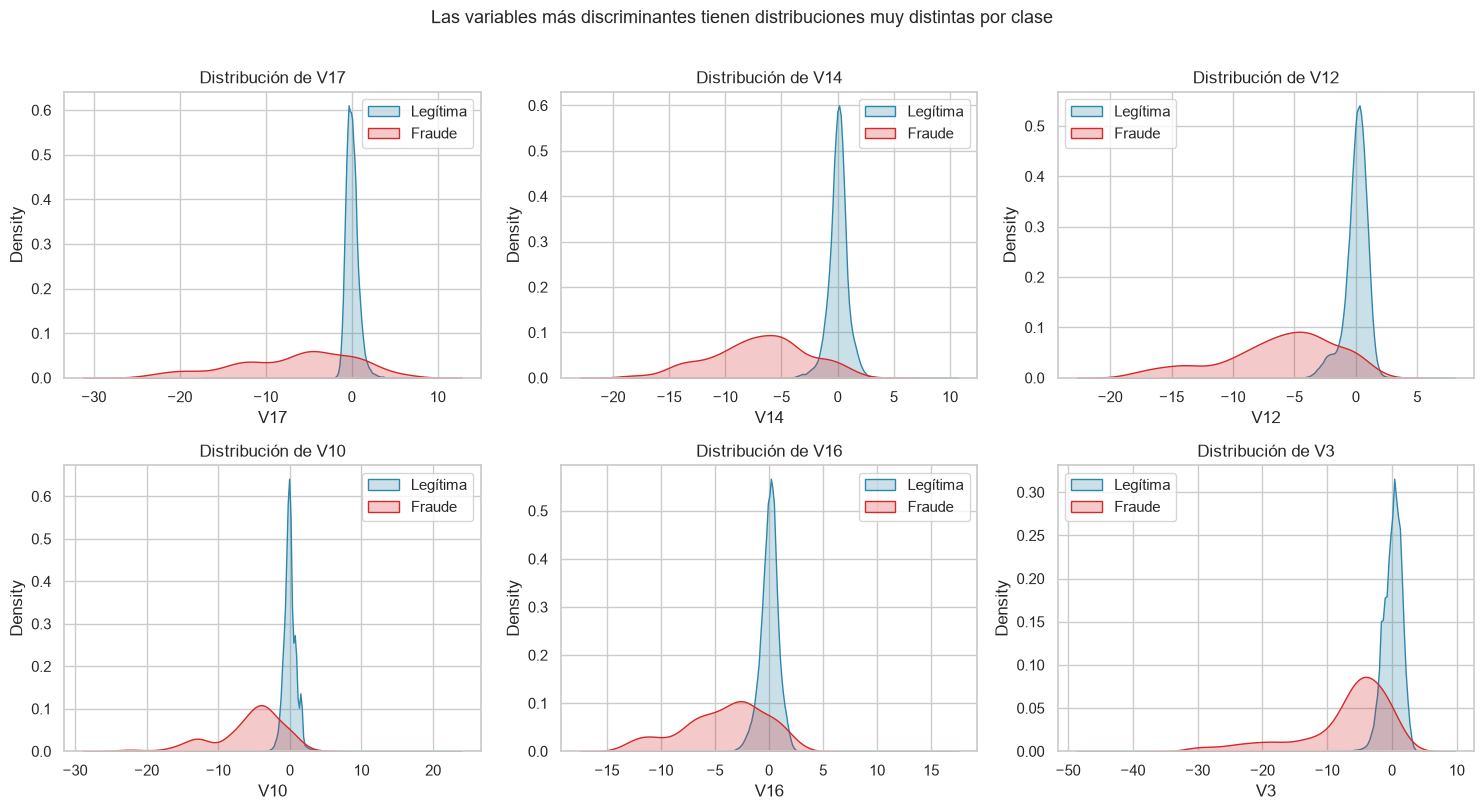

In [8]:
fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
for eje, var in zip(ejes.ravel(), top_variables):
    sns.kdeplot(df.loc[df["Class"] == 0, var], ax=eje, fill=True, color=COLOR_NORMAL, label="Legítima", common_norm=False)
    sns.kdeplot(df.loc[df["Class"] == 1, var], ax=eje, fill=True, color=COLOR_FRAUDE, label="Fraude", common_norm=False)
    eje.set_title(f"Distribución de {var}"); eje.legend()
plt.suptitle("Las variables más discriminantes tienen distribuciones muy distintas por clase", y=1.01, fontsize=13)
plt.tight_layout(); guardar(fig, "05_variables_discriminantes.png"); plt.show()

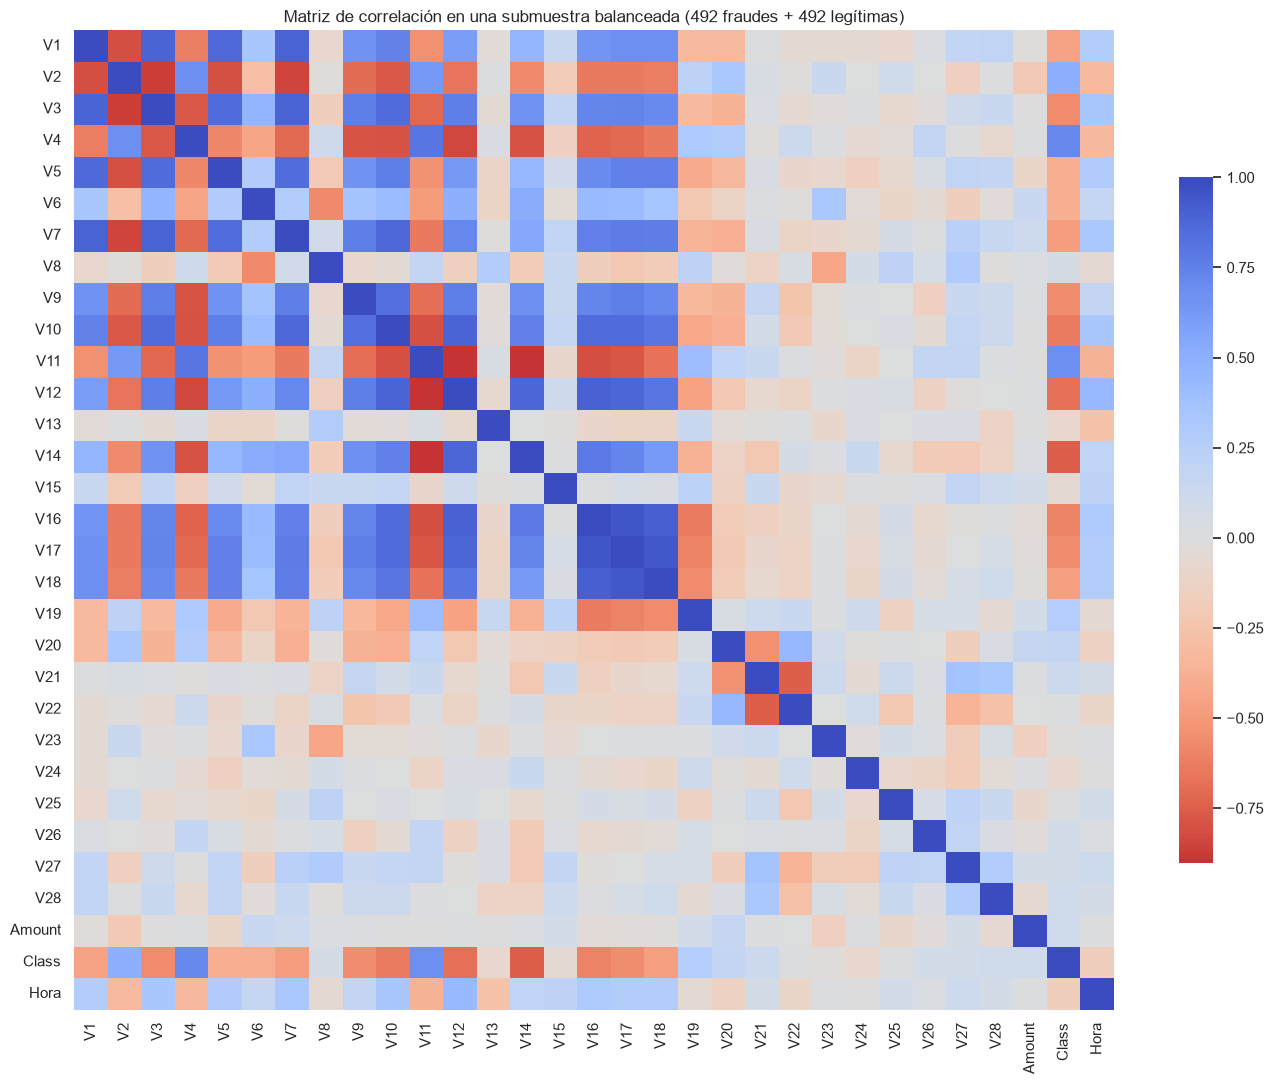

In [9]:
# Matriz de correlación en una muestra balanceada (en el dataset completo las V's son ~0 entre sí por el PCA)
muestra_bal = pd.concat([df[df["Class"] == 1], df[df["Class"] == 0].sample(492, random_state=SEED)])
fig, eje = plt.subplots(figsize=(14, 11))
sns.heatmap(muestra_bal.drop(columns=["Time"]).corr(), cmap="coolwarm_r", center=0, ax=eje, cbar_kws={"shrink": 0.7})
eje.set_title("Matriz de correlación en una submuestra balanceada (492 fraudes + 492 legítimas)")
plt.tight_layout(); guardar(fig, "06_matriz_correlacion_balanceada.png"); plt.show()

### ❓ Preguntas de la exploración

**1. ¿Qué tan desbalanceado está el dataset?**
Extremadamente: solo **492 de 284.807 transacciones (0,173 %) son fraude**, es decir ≈ 1 fraude por cada 578 transacciones legítimas. Este es el reto central del proyecto.

**2. ¿Por qué la *accuracy* (exactitud) no sirve como métrica aquí?**
Un modelo "tonto" que diga siempre *"legítima"* obtendría **99,83 % de accuracy** sin detectar un solo fraude. Por eso evaluamos con **Precision, Recall, F1, ROC-AUC, PR-AUC y la matriz de confusión**, que sí miden el desempeño sobre la clase minoritaria.

**3. ¿Qué variables son más útiles para detectar fraude?**
Las componentes **V14, V17, V12, V10, V16 y V3** (correlación negativa fuerte) y **V11, V4** (positiva). En las gráficas de densidad se ve que sus distribuciones para fraude están claramente desplazadas respecto a las legítimas.

**4. ¿Se identifican valores atípicos?**
Sí. `Amount` tiene una cola larga (hay transacciones de más de 25.000 €, mientras la mediana es ≈ 22 €). Por ello usamos **RobustScaler** (usa mediana y rango intercuartílico, no se deja dominar por los extremos). **No eliminamos atípicos**, porque en fraude *los atípicos son justamente la señal* que queremos detectar.

**5. ¿Hay patrones en el monto o en el horario?**
Los fraudes tienden a tener montos **más pequeños y más dispersos** (mediana ≈ 9 € vs 22 €), típico de "pruebas" con la tarjeta robada. Además, la **tasa de fraude se dispara en la madrugada** (≈ 2–4 a. m.), cuando hay pocas transacciones legítimas.

**6. ¿Hay datos faltantes o duplicados?**
No hay nulos. Hay **1.081 filas duplicadas**, que eliminamos en el preprocesamiento para no sobreestimar el desempeño (una misma fila podría quedar en entrenamiento y en prueba).

## Parte 3 — Preprocesamiento

Decisiones:
1. **Eliminar duplicados.**
2. **Ingeniería de variables:** reemplazar `Time` (segundos absolutos, no generaliza a otros días) por `Hora` del día.
3. **División estratificada** en tres conjuntos *antes de cualquier balanceo*:
   - **Entrenamiento (64 %)** → para ajustar los modelos (aquí y solo aquí se aplica SMOTE).
   - **Validación (16 %)** → para revisar el desempeño durante el desarrollo; junto con entrenamiento forma el 80 % sobre el que se hace la validación cruzada que elige el umbral y el modelo final (Parte 7).
   - **Prueba (20 %)** → datos nunca vistos, para reportar el desempeño final honesto.
4. **Escalado con RobustScaler** de `Amount` y `Hora` (las `V1–V28` ya vienen escaladas por el PCA).

In [10]:
filas_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicados eliminados: {filas_antes - len(df):,} → quedan {len(df):,} filas ({df['Class'].sum()} fraudes)")

VARIABLES = [f"V{i}" for i in range(1, 29)] + ["Amount", "Hora"]
X = df[VARIABLES]
y = df["Class"]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.20, stratify=y_temp, random_state=SEED)

particiones = pd.DataFrame({
    "Filas": [len(y_train), len(y_val), len(y_test)],
    "Fraudes": [y_train.sum(), y_val.sum(), y_test.sum()],
    "% Fraude": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=["Entrenamiento", "Validación", "Prueba"]).round(3)
particiones

Duplicados eliminados: 1,081 → quedan 283,726 filas (473 fraudes)


,Filas,Fraudes,% Fraude
Entrenamiento,181584,302,0.166
Validación,45396,76,0.167
Prueba,56746,95,0.167


In [11]:
# Preprocesador: RobustScaler para Amount y Hora; las V's pasan tal cual
preprocesador = ColumnTransformer(
    transformers=[("robusto", RobustScaler(), ["Amount", "Hora"])],
    remainder="passthrough",
    verbose_feature_names_out=False,
)
preprocesador.set_output(transform="pandas")
preprocesador.fit_transform(X_train).describe().loc[["mean", "50%", "std"], ["Amount", "Hora", "V1", "V14"]].round(3)

,Amount,Hora,V1,V14
mean,0.917,-0.106,0.003,-0.001
50%,0.000,0.000,0.017,0.050
std,3.409,0.647,1.951,0.956


### ❓ Preguntas del preprocesamiento

**¿Por qué se divide el dataset ANTES de aplicar SMOTE?**
Si se aplicara SMOTE sobre todo el dataset, los fraudes sintéticos se crearían interpolando fraudes que luego quedarían en el conjunto de prueba. El modelo "vería" información de la prueba (**fuga de datos / data leakage**) y las métricas serían irrealmente altas. Por eso SMOTE va **dentro de un `Pipeline` de imblearn**, que solo lo ejecuta en `fit` (entrenamiento) y nunca al predecir.

**¿Por qué estratificar la división?**
Con solo 0,17 % de fraudes, una división aleatoria simple podría dejar muy pocos fraudes en validación o prueba. `stratify=y` garantiza la misma proporción de fraude en los tres conjuntos (se ve en la tabla).

**¿Por qué RobustScaler y no StandardScaler para `Amount`?**
`Amount` tiene atípicos extremos. StandardScaler usa media y desviación estándar, que se distorsionan con esos valores; RobustScaler usa **mediana y rango intercuartílico**, mucho más estables.

## Parte 4 — Balanceo de clases con SMOTE

**SMOTE** (*Synthetic Minority Over-sampling Technique*) crea fraudes **sintéticos**: toma un fraude, busca sus *k* vecinos más cercanos (también fraudes, k = 5 por defecto) y genera nuevos puntos sobre el segmento que los une:

$$x_{nuevo} = x_i + \lambda \cdot (x_{vecino} - x_i), \quad \lambda \sim U(0,1)$$

A diferencia de duplicar fraudes (*random oversampling*), SMOTE genera ejemplos nuevos y reduce el sobreajuste.

,Antes de SMOTE,Después de SMOTE
Legítima,181282,181282
Fraude,302,181282


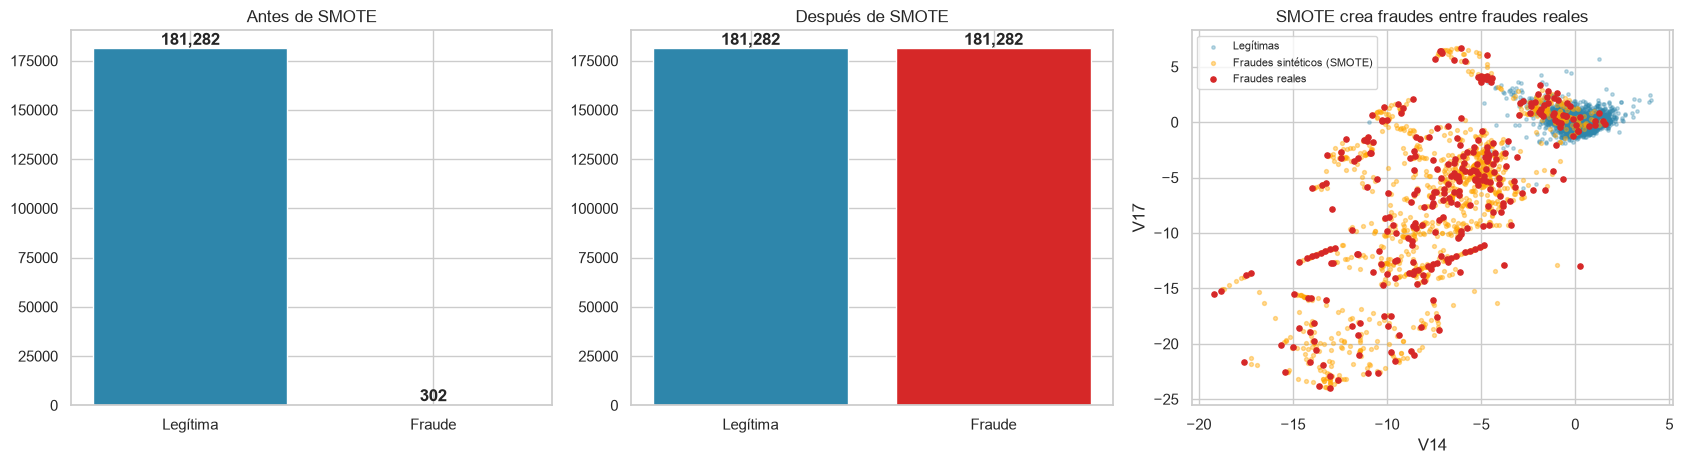

In [12]:
X_train_prep = preprocesador.fit_transform(X_train)
smote_demo = SMOTE(random_state=SEED)
X_train_smote, y_train_smote = smote_demo.fit_resample(X_train_prep, y_train)

antes = y_train.value_counts().sort_index()
despues = y_train_smote.value_counts().sort_index()
display(pd.DataFrame({"Antes de SMOTE": antes, "Después de SMOTE": despues}, index=[0, 1]).rename(index={0: "Legítima", 1: "Fraude"}))

fig, ejes = plt.subplots(1, 3, figsize=(17, 4.8))
for eje, datos, titulo in [(ejes[0], antes, "Antes de SMOTE"), (ejes[1], despues, "Después de SMOTE")]:
    barras = eje.bar(["Legítima", "Fraude"], datos.values, color=[COLOR_NORMAL, COLOR_FRAUDE])
    eje.set_title(titulo)
    for b, v in zip(barras, datos.values):
        eje.text(b.get_x() + b.get_width() / 2, v, f"{v:,}", ha="center", va="bottom", fontweight="bold")

# SMOTE agrega las muestras sintéticas al final del arreglo
n_original = len(X_train_prep)
sinteticos = X_train_smote.iloc[n_original:].sample(1500, random_state=SEED)
normales = X_train_prep[y_train.values == 0].sample(3000, random_state=SEED)
fraudes_reales = X_train_prep[y_train.values == 1]
ejes[2].scatter(normales["V14"], normales["V17"], s=6, alpha=0.3, c=COLOR_NORMAL, label="Legítimas")
ejes[2].scatter(sinteticos["V14"], sinteticos["V17"], s=8, alpha=0.4, c="orange", label="Fraudes sintéticos (SMOTE)")
ejes[2].scatter(fraudes_reales["V14"], fraudes_reales["V17"], s=14, c=COLOR_FRAUDE, label="Fraudes reales")
ejes[2].set_xlabel("V14"); ejes[2].set_ylabel("V17"); ejes[2].legend(fontsize=8)
ejes[2].set_title("SMOTE crea fraudes entre fraudes reales")
plt.tight_layout(); guardar(fig, "07_balanceo_smote.png"); plt.show()

### ❓ Preguntas sobre SMOTE

**¿Por qué es necesario balancear?**
Con 1 fraude por cada ~578 legítimas, los algoritmos minimizan el error global "aprendiendo" a ignorar la clase minoritaria. Al balancear, el modelo recibe suficientes ejemplos de fraude para aprender sus patrones y el **Recall** (fraudes detectados) mejora.

**¿Qué riesgos tiene SMOTE?**
(1) Puede generar puntos en zonas donde hay legítimas, lo que aumenta los **falsos positivos** (baja la Precision); (2) si se aplica antes de dividir los datos produce fuga de información. Lo mitigamos aplicándolo solo al entrenamiento y **ajustando el umbral de decisión** en la Parte 7.

**¿SMOTE se aplica a validación y prueba?**
**No.** Esos conjuntos deben conservar la distribución real (0,17 % de fraude) para medir cómo funcionaría el sistema en producción.

## Parte 5 — Modelado

Entrenamos varios modelos, todos dentro de un `Pipeline` **[preprocesamiento → SMOTE → (estandarizar) → modelo]**:

| Modelo | Tipo | Idea clave |
|---|---|---|
| Regresión Logística | Lineal | Línea base para comparar |
| **Random Forest** | *Bagging* de árboles | Muchos árboles entrenados con muestras y variables aleatorias; vota la mayoría → robusto y poco sobreajuste |
| **XGBoost** | *Boosting* de árboles | Árboles secuenciales: cada uno corrige los errores del anterior (descenso de gradiente) con regularización |
| **Red Neuronal MLP** | Aprendizaje profundo | 3 capas ocultas (64-32-16 neuronas, ReLU) que aprenden relaciones no lineales |

Además entrenamos **Random Forest y XGBoost SIN SMOTE** para medir objetivamente el aporte del balanceo.

In [13]:
def pipeline_modelo(clasificador, usar_smote=True, estandarizar=False):
    pasos = [("preprocesamiento", clone(preprocesador))]
    if usar_smote:
        pasos.append(("smote", SMOTE(random_state=SEED)))
    if estandarizar:
        pasos.append(("estandarizar", StandardScaler()))
    pasos.append(("modelo", clasificador))
    return ImbPipeline(pasos)


def crear_random_forest():
    return RandomForestClassifier(n_estimators=150, max_depth=18, min_samples_leaf=2,
                                  n_jobs=-1, random_state=SEED)


def crear_xgboost():
    return XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8,
                         colsample_bytree=0.8, tree_method="hist", eval_metric="aucpr",
                         n_jobs=-1, random_state=SEED)


modelos = {
    "Regresión Logística + SMOTE": pipeline_modelo(LogisticRegression(max_iter=2000), estandarizar=True),
    "Random Forest (sin SMOTE)": pipeline_modelo(crear_random_forest(), usar_smote=False),
    "Random Forest + SMOTE": pipeline_modelo(crear_random_forest()),
    "XGBoost (sin SMOTE)": pipeline_modelo(crear_xgboost(), usar_smote=False),
    "XGBoost + SMOTE": pipeline_modelo(crear_xgboost()),
    "Red Neuronal MLP + SMOTE": pipeline_modelo(
        MLPClassifier(hidden_layer_sizes=(64, 32, 16), activation="relu", alpha=1e-4,
                      batch_size=512, learning_rate_init=1e-3, max_iter=40,
                      early_stopping=True, n_iter_no_change=5, random_state=SEED),
        estandarizar=True),
}

prob_val, prob_test, tiempos = {}, {}, {}
for nombre, modelo in modelos.items():
    inicio = time.time()
    modelo.fit(X_train, y_train)
    tiempos[nombre] = time.time() - inicio
    prob_val[nombre] = modelo.predict_proba(X_val)[:, 1]
    prob_test[nombre] = modelo.predict_proba(X_test)[:, 1]
    print(f"✔ {nombre:<30} entrenado en {tiempos[nombre]:6.1f} s")

✔ Regresión Logística + SMOTE    entrenado en    2.1 s


✔ Random Forest (sin SMOTE)      entrenado en   20.6 s


✔ Random Forest + SMOTE          entrenado en   37.9 s


✔ XGBoost (sin SMOTE)            entrenado en    4.0 s


✔ XGBoost + SMOTE                entrenado en    6.5 s


✔ Red Neuronal MLP + SMOTE       entrenado en   10.9 s


## Parte 6 — Evaluación en el conjunto de PRUEBA (umbral por defecto = 0,5)

| Métrica | Pregunta que responde |
|---|---|
| **Precision** = TP / (TP + FP) | De las alertas que lanzó el sistema, ¿cuántas eran fraude de verdad? |
| **Recall** = TP / (TP + FN) | De todos los fraudes reales, ¿cuántos detectó? |
| **F1** | Media armónica de Precision y Recall (equilibrio entre ambas) |
| **ROC-AUC** | Capacidad de ordenar fraudes por encima de legítimas, para cualquier umbral |
| **PR-AUC** (Average Precision) | Igual que ROC-AUC pero centrada en la clase minoritaria; más exigente con datos desbalanceados |

In [14]:
def calcular_metricas(y_real, probabilidades, umbral=0.5):
    pred = (probabilidades >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred).ravel()
    return {
        "Precision": precision_score(y_real, pred, zero_division=0),
        "Recall": recall_score(y_real, pred),
        "F1": f1_score(y_real, pred),
        "ROC-AUC": roc_auc_score(y_real, probabilidades),
        "PR-AUC": average_precision_score(y_real, probabilidades),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }


tabla_05 = pd.DataFrame({n: calcular_metricas(y_test, p) for n, p in prob_test.items()}).T
tabla_05["Tiempo (s)"] = pd.Series(tiempos)
tabla_05 = tabla_05.sort_values("F1", ascending=False)
tabla_05.style.format({c: "{:.4f}" for c in ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]} | {"Tiempo (s)": "{:.1f}"} | {c: "{:.0f}" for c in ["TP", "FP", "FN", "TN"]}) \
    .background_gradient(subset=["F1", "ROC-AUC", "PR-AUC"], cmap="Greens")

,Precision,Recall,F1,ROC-AUC,PR-AUC,TP,FP,FN,TN,Tiempo (s)
XGBoost (sin SMOTE),0.9859,0.7368,0.8434,0.9696,0.8335,70,1,25,56650,4.0
Random Forest (sin SMOTE),0.9583,0.7263,0.8263,0.9560,0.7989,69,3,26,56648,20.6
Random Forest + SMOTE,0.8152,0.7895,0.8021,0.9738,0.8086,75,17,20,56634,37.9
XGBoost + SMOTE,0.7353,0.7895,0.7614,0.9673,0.8076,75,27,20,56624,6.5
Red Neuronal MLP + SMOTE,0.8049,0.6947,0.7458,0.9241,0.7315,66,16,29,56635,10.9
Regresión Logística + SMOTE,0.0488,0.8737,0.0924,0.9552,0.6757,83,1619,12,55032,2.1


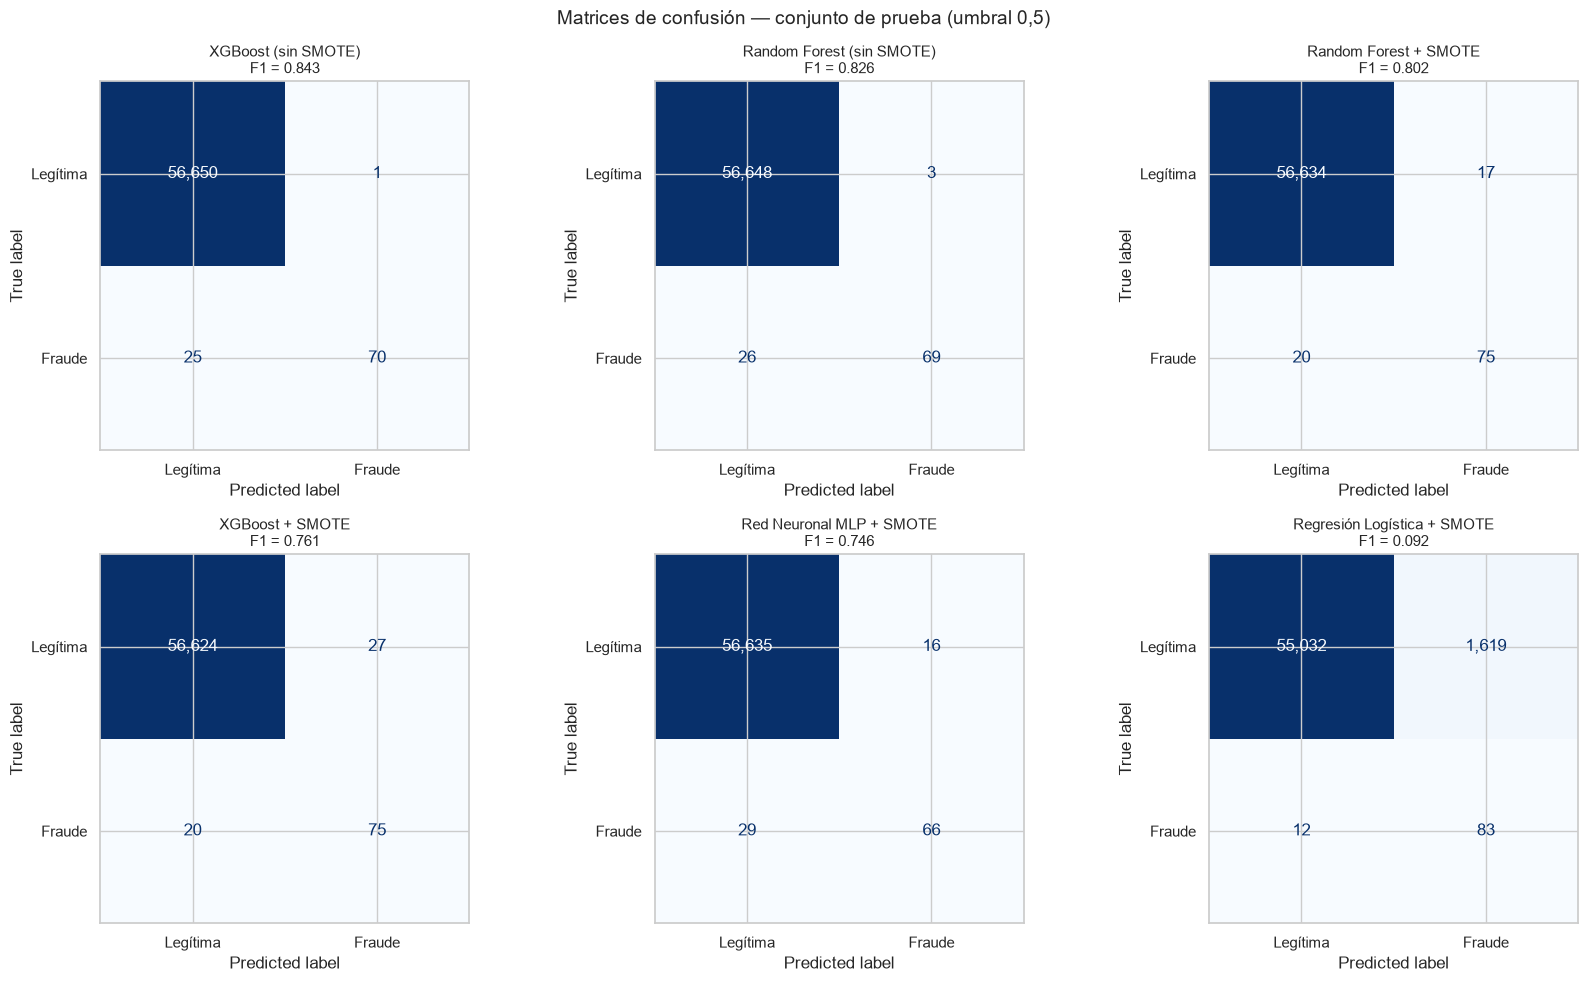

In [15]:
# Matrices de confusión de todos los modelos
fig, ejes = plt.subplots(2, 3, figsize=(17, 10))
for eje, nombre in zip(ejes.ravel(), tabla_05.index):
    cm = confusion_matrix(y_test, (prob_test[nombre] >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Legítima", "Fraude"]).plot(ax=eje, cmap="Blues", colorbar=False, values_format=",")
    eje.set_title(f"{nombre}\nF1 = {tabla_05.loc[nombre, 'F1']:.3f}", fontsize=11)
plt.suptitle("Matrices de confusión — conjunto de prueba (umbral 0,5)", fontsize=14)
plt.tight_layout(); guardar(fig, "08_matrices_confusion.png"); plt.show()

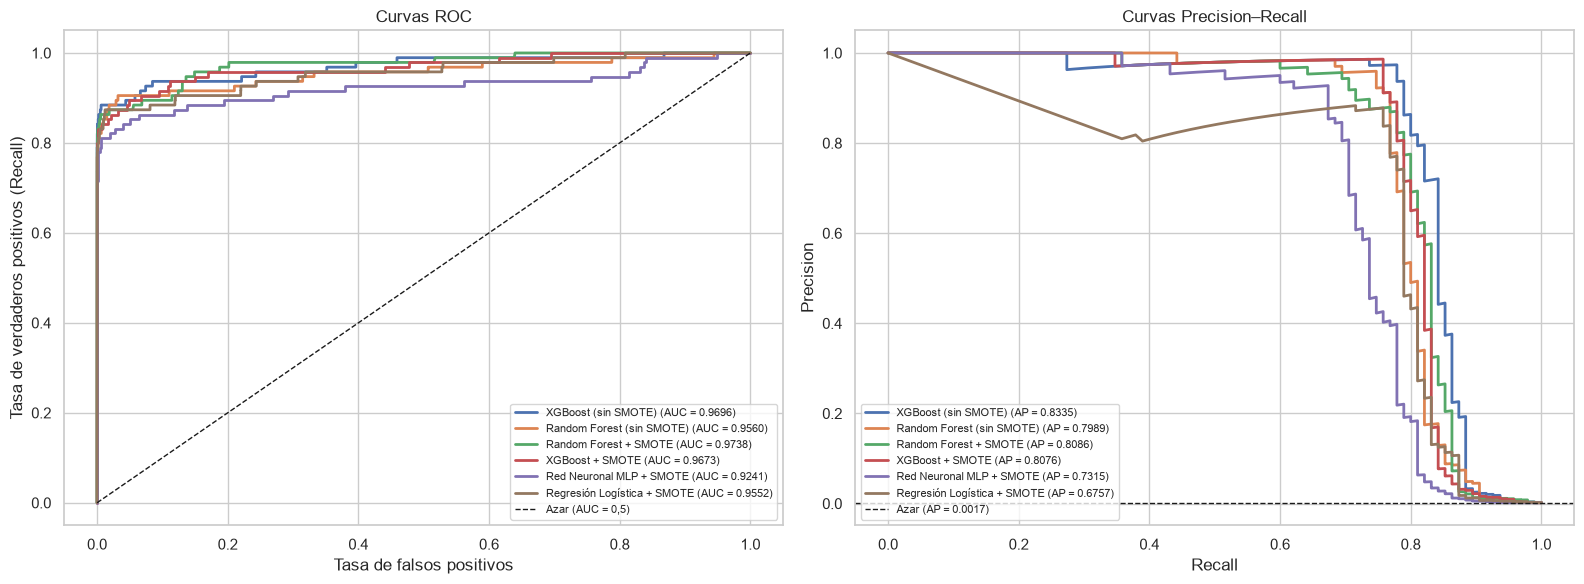

In [16]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 6))
for nombre in tabla_05.index:
    fpr, tpr, _ = roc_curve(y_test, prob_test[nombre])
    ejes[0].plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {tabla_05.loc[nombre, 'ROC-AUC']:.4f})")
    prec, rec, _ = precision_recall_curve(y_test, prob_test[nombre])
    ejes[1].plot(rec, prec, lw=2, label=f"{nombre} (AP = {tabla_05.loc[nombre, 'PR-AUC']:.4f})")
ejes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0,5)")
ejes[0].set_xlabel("Tasa de falsos positivos"); ejes[0].set_ylabel("Tasa de verdaderos positivos (Recall)")
ejes[0].set_title("Curvas ROC"); ejes[0].legend(fontsize=8, loc="lower right")
ejes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Azar (AP = {y_test.mean():.4f})")
ejes[1].set_xlabel("Recall"); ejes[1].set_ylabel("Precision")
ejes[1].set_title("Curvas Precision–Recall"); ejes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout(); guardar(fig, "09_curvas_roc_y_precision_recall.png"); plt.show()

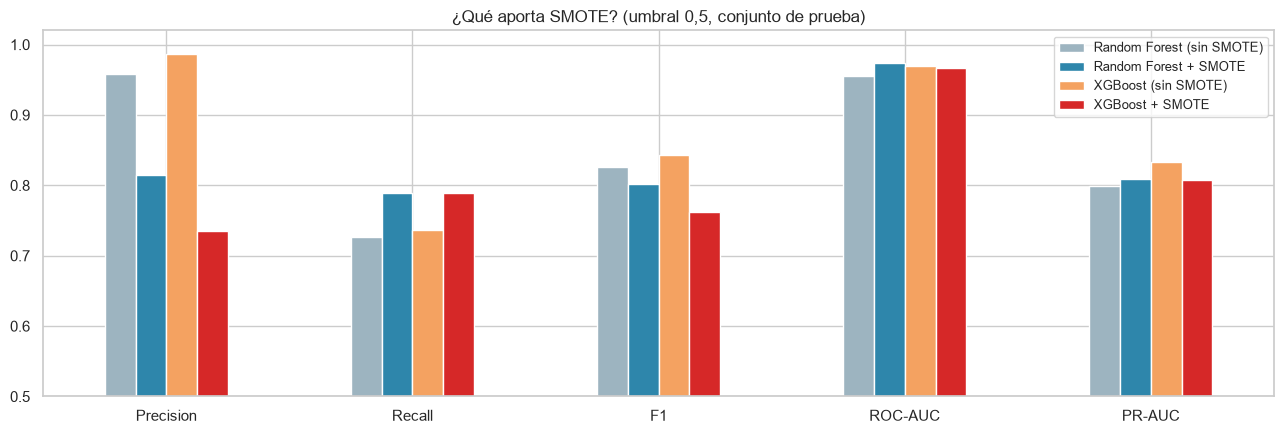

,Precision,Recall,F1,ROC-AUC,PR-AUC
Random Forest (sin SMOTE),0.9583,0.7263,0.8263,0.9560,0.7989
Random Forest + SMOTE,0.8152,0.7895,0.8021,0.9738,0.8086
XGBoost (sin SMOTE),0.9859,0.7368,0.8434,0.9696,0.8335
XGBoost + SMOTE,0.7353,0.7895,0.7614,0.9673,0.8076


In [17]:
# Efecto de SMOTE: comparación directa
comparacion_smote = tabla_05.loc[["Random Forest (sin SMOTE)", "Random Forest + SMOTE",
                                  "XGBoost (sin SMOTE)", "XGBoost + SMOTE"],
                                 ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]]
fig, eje = plt.subplots(figsize=(13, 4.5))
comparacion_smote.T.plot(kind="bar", ax=eje, color=["#9DB4C0", COLOR_NORMAL, "#F4A261", COLOR_FRAUDE])
eje.set_ylim(0.5, 1.02); eje.set_title("¿Qué aporta SMOTE? (umbral 0,5, conjunto de prueba)")
eje.tick_params(axis="x", rotation=0); eje.legend(fontsize=9)
plt.tight_layout(); guardar(fig, "10_efecto_smote.png"); plt.show()
comparacion_smote.round(4)

### ❓ Interpretación de la evaluación con umbral 0,5

- **SMOTE aumenta el Recall** (se detectan más fraudes) a costa de más **falsos positivos** (baja la Precision). Es el comportamiento esperado: el modelo se vuelve más "sensible" a la clase minoritaria.
- **ROC-AUC es alta (> 0,95) en casi todos los modelos**, pero con datos tan desbalanceados la ROC-AUC es optimista: incluso con muchos falsos positivos la tasa de falsos positivos sigue siendo baja porque hay ~57.000 legítimas. Por eso también reportamos **PR-AUC**, que es más honesta en este escenario.
- La **regresión logística** con SMOTE detecta muchos fraudes pero genera más de 1.600 falsas alarmas → justifica usar modelos de ensamble no lineales.
- **Hallazgo importante (análisis crítico):** con umbral 0,5, los modelos **sin SMOTE** obtienen mayor Precision y F1, mientras que **con SMOTE** se detectan más fraudes (Recall 0,79 vs 0,73). La PR-AUC (que no depende del umbral) es muy parecida con y sin SMOTE. Es decir, en este dataset **SMOTE no crea información nueva**: desplaza el punto de operación del modelo hacia "detectar más". Esto coincide con lo reportado en la literatura para árboles de ensamble y muestra por qué **el umbral debe calibrarse después del balanceo**.
- El umbral 0,5 **no es necesariamente el mejor**: después de SMOTE los modelos tienden a asignar probabilidades altas al fraude. En la siguiente parte lo optimizamos.

## Parte 7 — Optimización del umbral de decisión

El modelo entrega una **probabilidad de fraude**; el umbral decide a partir de qué probabilidad se lanza una alerta.

**Política de negocio adoptada:** el banco quiere detectar **al menos el 80 % de los fraudes** (Recall ≥ 0,80). Entre todos los umbrales que cumplen esa condición escogemos el que **maximiza el F1** (el que genera menos falsas alarmas).

**¿Con qué datos se elige el umbral?** Con predicciones **out-of-fold** de una **validación cruzada estratificada de 5 folds** sobre entrenamiento + validación (80 % de los datos, ≈ 380 fraudes): cada transacción recibe la probabilidad de un modelo que *no* la vio al entrenar. **Nunca se usa el conjunto de prueba**, que queda solo para reportar.

> **Lección aprendida durante el proyecto:** en una primera versión elegimos el umbral con el conjunto de validación simple (solo 76 fraudes). El umbral "óptimo" salió en ≈ 0,95 para XGBoost + SMOTE y en prueba el Recall cayó al 70 % — el umbral estaba sobreajustado a esos pocos fraudes. Con validación cruzada el umbral es mucho más estable.

In [18]:
RECALL_MINIMO = 0.80  # política de negocio: detectar al menos el 80 % de los fraudes


def mejor_umbral(y_real, probabilidades, recall_minimo=RECALL_MINIMO):
    prec, rec, umbrales = precision_recall_curve(y_real, probabilidades)
    prec, rec = prec[:-1], rec[:-1]
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    f1_restringido = np.where(rec >= recall_minimo, f1, -1)  # descarta umbrales que no cumplen la política
    i = int(np.argmax(f1_restringido)) if f1_restringido.max() >= 0 else int(np.nanargmax(f1))
    return float(umbrales[i]), float(f1[i])


from sklearn.model_selection import cross_val_predict

cv_umbral = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
prob_oof = {}
for nombre, modelo in modelos.items():
    inicio = time.time()
    prob_oof[nombre] = cross_val_predict(clone(modelo), X_temp, y_temp, cv=cv_umbral, method="predict_proba")[:, 1]
    print(f"✔ Predicciones out-of-fold de {nombre:<30} ({time.time() - inicio:5.1f} s)")

umbrales_opt, filas = {}, []
for nombre in modelos:
    umbral, f1_val = mejor_umbral(y_temp, prob_oof[nombre])
    umbrales_opt[nombre] = umbral
    m = calcular_metricas(y_test, prob_test[nombre], umbral)
    filas.append({"Modelo": nombre, "Umbral óptimo": umbral, "F1 validación (CV)": f1_val, **m})

tabla_opt = pd.DataFrame(filas).set_index("Modelo").sort_values("F1 validación (CV)", ascending=False)
tabla_opt.style.format({c: "{:.4f}" for c in ["Umbral óptimo", "F1 validación (CV)", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]} | {c: "{:.0f}" for c in ["TP", "FP", "FN", "TN"]}) \
    .background_gradient(subset=["F1 validación (CV)", "F1"], cmap="Greens")

✔ Predicciones out-of-fold de Regresión Logística + SMOTE    (  8.0 s)


✔ Predicciones out-of-fold de Random Forest (sin SMOTE)      (107.3 s)


✔ Predicciones out-of-fold de Random Forest + SMOTE          (185.4 s)


✔ Predicciones out-of-fold de XGBoost (sin SMOTE)            ( 16.8 s)


✔ Predicciones out-of-fold de XGBoost + SMOTE                ( 30.5 s)


✔ Predicciones out-of-fold de Red Neuronal MLP + SMOTE       ( 41.7 s)


,Umbral óptimo,F1 validación (CV),Precision,Recall,F1,ROC-AUC,PR-AUC,TP,FP,FN,TN
Modelo,,,,,,,,,,,
XGBoost (sin SMOTE),0.3022,0.8729,0.9730,0.7579,0.8521,0.9696,0.8335,72,2,23,56649
XGBoost + SMOTE,0.9677,0.8727,0.9851,0.6947,0.8148,0.9673,0.8076,66,1,29,56650
Random Forest (sin SMOTE),0.4122,0.8604,0.9595,0.7474,0.8402,0.9560,0.7989,71,3,24,56648
Random Forest + SMOTE,0.6167,0.8359,0.8861,0.7368,0.8046,0.9738,0.8086,70,9,25,56642
Regresión Logística + SMOTE,1.0000,0.7769,0.7935,0.7684,0.7807,0.9552,0.6757,73,19,22,56632
Red Neuronal MLP + SMOTE,0.2136,0.7086,0.7444,0.7053,0.7243,0.9241,0.7315,67,23,28,56628


🏆 Modelo final seleccionado: XGBoost + SMOTE
   Umbral de alerta: 0.9677

Reporte de clasificación (conjunto de prueba):
              precision    recall  f1-score   support

    Legítima     0.9995    1.0000    0.9997     56651
      Fraude     0.9851    0.6947    0.8148        95

    accuracy                         0.9995     56746
   macro avg     0.9923    0.8474    0.9073     56746
weighted avg     0.9995    0.9995    0.9994     56746



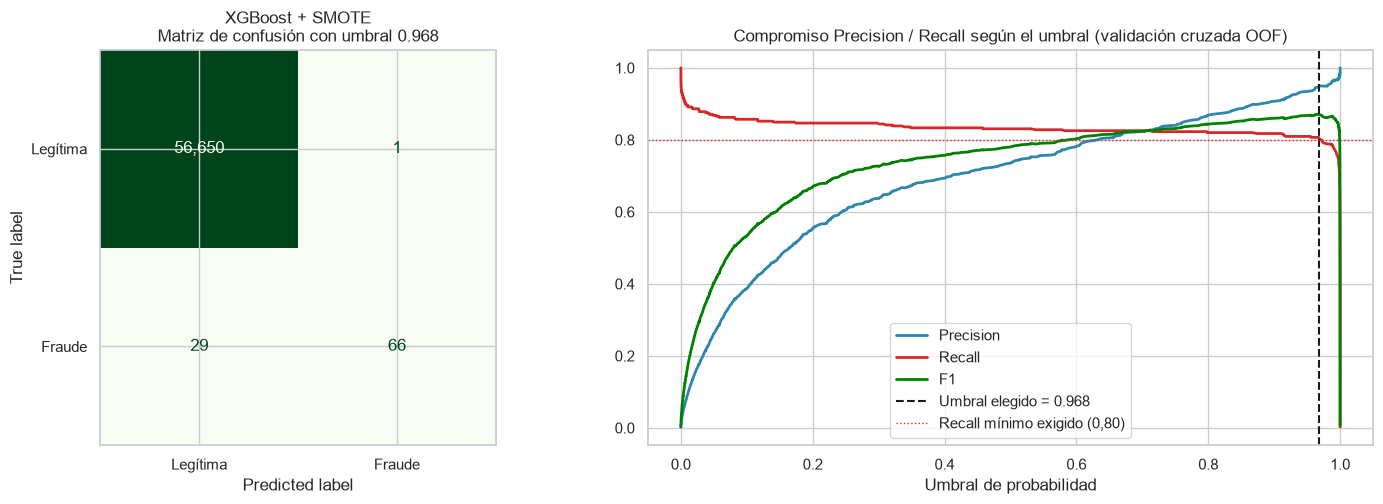

In [19]:
# Selección del modelo final: el de mayor F1 en VALIDACIÓN (cumpliendo Recall >= 0,80) entre los modelos con SMOTE (requerimiento del proyecto)
candidatos = [n for n in tabla_opt.index if "SMOTE" in n and "sin SMOTE" not in n]
MODELO_FINAL = tabla_opt.loc[candidatos, "F1 validación (CV)"].idxmax()
UMBRAL_FINAL = umbrales_opt[MODELO_FINAL]
print(f"🏆 Modelo final seleccionado: {MODELO_FINAL}")
print(f"   Umbral de alerta: {UMBRAL_FINAL:.4f}")

pred_final = (prob_test[MODELO_FINAL] >= UMBRAL_FINAL).astype(int)
print("\nReporte de clasificación (conjunto de prueba):")
print(classification_report(y_test, pred_final, target_names=["Legítima", "Fraude"], digits=4))

fig, ejes = plt.subplots(1, 2, figsize=(15, 5.2))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_final), display_labels=["Legítima", "Fraude"]) \
    .plot(ax=ejes[0], cmap="Greens", colorbar=False, values_format=",")
ejes[0].set_title(f"{MODELO_FINAL}\nMatriz de confusión con umbral {UMBRAL_FINAL:.3f}")
prec, rec, umb = precision_recall_curve(y_temp, prob_oof[MODELO_FINAL])
ejes[1].plot(umb, prec[:-1], label="Precision", lw=2, color=COLOR_NORMAL)
ejes[1].plot(umb, rec[:-1], label="Recall", lw=2, color=COLOR_FRAUDE)
ejes[1].plot(umb, 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None), label="F1", lw=2, color="green")
ejes[1].axvline(UMBRAL_FINAL, color="k", ls="--", label=f"Umbral elegido = {UMBRAL_FINAL:.3f}")
ejes[1].axhline(RECALL_MINIMO, color=COLOR_FRAUDE, ls=":", lw=1, label="Recall mínimo exigido (0,80)")
ejes[1].set_xlabel("Umbral de probabilidad"); ejes[1].set_title("Compromiso Precision / Recall según el umbral (validación cruzada OOF)")
ejes[1].legend()
plt.tight_layout(); guardar(fig, "11_modelo_final_umbral.png"); plt.show()

### 💰 Impacto de negocio del modelo final
Traducimos la matriz de confusión a dinero en el conjunto de prueba.

In [20]:
montos = X_test["Amount"].values
y_arr = y_test.values
impacto = {
    "Fraudes en prueba": int(y_arr.sum()),
    "Fraudes detectados (TP)": int(((pred_final == 1) & (y_arr == 1)).sum()),
    "Fraudes no detectados (FN)": int(((pred_final == 0) & (y_arr == 1)).sum()),
    "Falsas alarmas (FP)": int(((pred_final == 1) & (y_arr == 0)).sum()),
    "Monto total en fraude (€)": float(montos[y_arr == 1].sum()),
    "Monto de fraude detectado (€)": float(montos[(pred_final == 1) & (y_arr == 1)].sum()),
    "Monto de fraude no detectado (€)": float(montos[(pred_final == 0) & (y_arr == 1)].sum()),
}
impacto["% del dinero en fraude protegido"] = impacto["Monto de fraude detectado (€)"] / impacto["Monto total en fraude (€)"] * 100
impacto["Alertas revisadas por cada fraude real"] = (impacto["Fraudes detectados (TP)"] + impacto["Falsas alarmas (FP)"]) / max(impacto["Fraudes detectados (TP)"], 1)
pd.Series(impacto).to_frame("Valor").style.format("{:,.2f}")

,Valor
Fraudes en prueba,95.00
Fraudes detectados (TP),66.00
Fraudes no detectados (FN),29.00
Falsas alarmas (FP),1.00
Monto total en fraude (€),"14,766.31"
Monto de fraude detectado (€),"8,876.90"
Monto de fraude no detectado (€),"5,889.41"
% del dinero en fraude protegido,60.12
Alertas revisadas por cada fraude real,1.02


### ❓ Preguntas sobre el umbral y la selección del modelo

**¿Por qué no usar siempre 0,5 como umbral?**
Porque el costo de los errores no es simétrico y SMOTE desplaza las probabilidades. Subir el umbral reduce falsas alarmas (sube Precision) y bajarlo detecta más fraudes (sube Recall). El umbral óptimo depende de cuánto le cuesta al banco un fraude no detectado vs. revisar una alerta falsa.

**¿Qué es más grave, un falso positivo o un falso negativo?**
En fraude, generalmente el **falso negativo** (fraude no detectado → pérdida directa de dinero y de confianza del cliente). Pero demasiados falsos positivos bloquean tarjetas de clientes honestos y saturan al equipo de revisión. El F1 equilibra ambos; en la aplicación web el umbral puede ajustarse según la política del banco.

**¿Por qué se eligió el umbral con validación y no con prueba?**
Si se ajusta el umbral mirando la prueba, ese conjunto deja de ser "nunca visto" y las métricas se inflan. Validación sirve para decidir; prueba solo para reportar.

## Parte 8 — Interpretabilidad: importancia de las variables

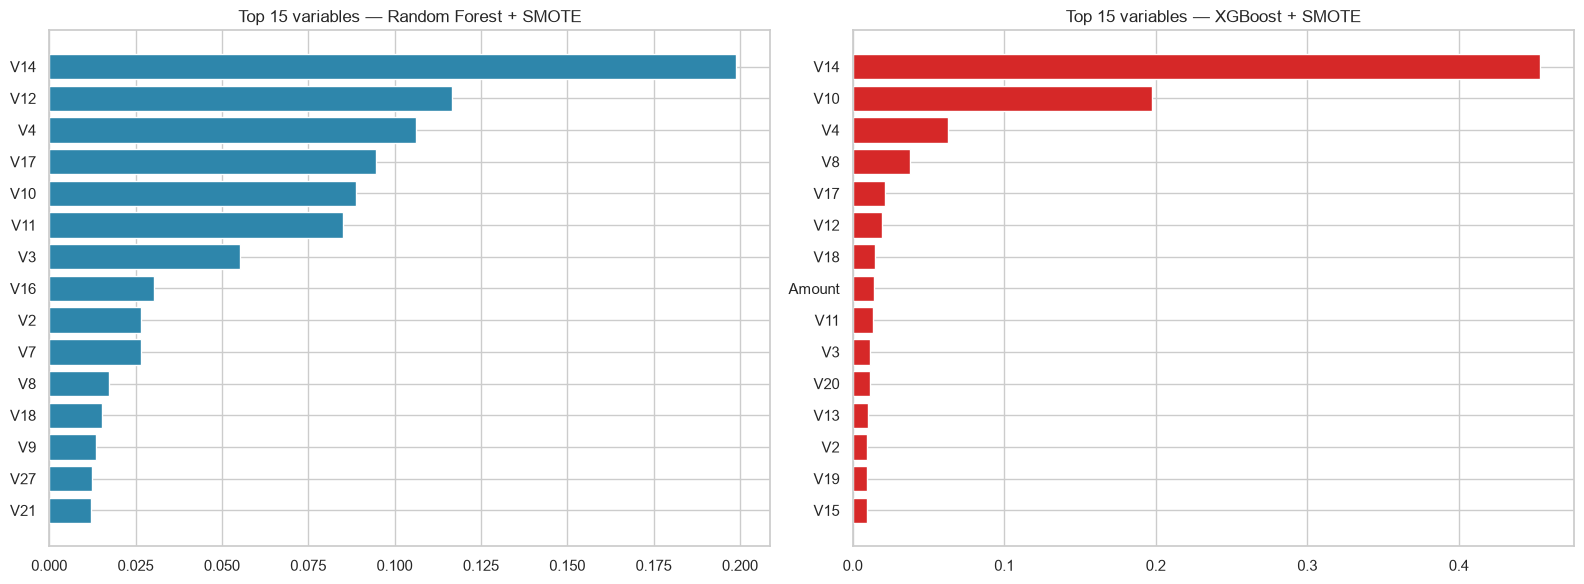

Top 5 Random Forest: ['V14', 'V12', 'V4', 'V17', 'V10']
Top 5 XGBoost:       ['V14', 'V10', 'V4', 'V8', 'V17']


In [21]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 6))
for eje, nombre, color in [(ejes[0], "Random Forest + SMOTE", COLOR_NORMAL), (ejes[1], "XGBoost + SMOTE", COLOR_FRAUDE)]:
    modelo = modelos[nombre]
    nombres_vars = modelo.named_steps["preprocesamiento"].get_feature_names_out()
    imp = pd.Series(modelo.named_steps["modelo"].feature_importances_, index=nombres_vars).sort_values().tail(15)
    eje.barh(imp.index, imp.values, color=color)
    eje.set_title(f"Top 15 variables — {nombre}")
plt.tight_layout(); guardar(fig, "12_importancia_variables.png"); plt.show()

importancia_xgb = pd.Series(modelos["XGBoost + SMOTE"].named_steps["modelo"].feature_importances_,
                            index=modelos["XGBoost + SMOTE"].named_steps["preprocesamiento"].get_feature_names_out()).sort_values(ascending=False)
importancia_rf = pd.Series(modelos["Random Forest + SMOTE"].named_steps["modelo"].feature_importances_,
                           index=modelos["Random Forest + SMOTE"].named_steps["preprocesamiento"].get_feature_names_out()).sort_values(ascending=False)
print("Top 5 Random Forest:", importancia_rf.head(5).index.tolist())
print("Top 5 XGBoost:      ", importancia_xgb.head(5).index.tolist())

**Interpretación:** ambos modelos coinciden en que las componentes **V14, V4, V10, V17 y V12** están entre las más importantes, lo mismo que se observó en el EDA (Parte 2.4). Esto da confianza en que los modelos aprendieron patrones reales y no ruido. Como las V's provienen de PCA no se pueden interpretar directamente (p. ej. "país" o "comercio"), pero el banco, que conoce la transformación, sí podría hacerlo.

## Parte 9 — Validación cruzada estratificada (5 folds)

Para comprobar que los resultados **no dependen de una única partición**, evaluamos Random Forest + SMOTE y XGBoost + SMOTE con validación cruzada estratificada de 5 folds sobre entrenamiento + validación. SMOTE se aplica dentro de cada fold (gracias al Pipeline), sin fuga de datos.

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metricas_cv = {"precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}
resultados_cv = {}
for nombre in ["Random Forest + SMOTE", "XGBoost + SMOTE"]:
    inicio = time.time()
    r = cross_validate(clone(modelos[nombre]), X_temp, y_temp, cv=cv, scoring=metricas_cv, n_jobs=1)
    resultados_cv[nombre] = {m: (r[f"test_{m}"].mean(), r[f"test_{m}"].std()) for m in metricas_cv}
    print(f"✔ {nombre} validado en {time.time() - inicio:.0f} s")

tabla_cv = pd.DataFrame({n: {m.upper(): f"{v[0]:.4f} ± {v[1]:.4f}" for m, v in res.items()} for n, res in resultados_cv.items()}).T
tabla_cv

✔ Random Forest + SMOTE validado en 182 s


✔ XGBoost + SMOTE validado en 28 s


,PRECISION,RECALL,F1,ROC_AUC,PR_AUC
Random Forest + SMOTE,0.8194 ± 0.0465,0.8227 ± 0.0462,0.8195 ± 0.0285,0.9765 ± 0.0124,0.8364 ± 0.0321
XGBoost + SMOTE,0.7386 ± 0.0431,0.8307 ± 0.0395,0.7805 ± 0.0246,0.9747 ± 0.0079,0.8458 ± 0.0308


**Interpretación:** la desviación estándar entre folds es pequeña, lo que indica que los modelos son **estables**: su desempeño no se debe a una partición "afortunada" de los datos.

## Parte 10 — Exportación de modelos y datos para la aplicación web
Se guardan en `03_Modelos_Entrenados`:
- Los pipelines completos (preprocesamiento + SMOTE + modelo) en formato `.joblib`.
- `metadata_modelos.json`: variables, umbrales óptimos, métricas y modelo final.
- `transacciones_prueba.parquet`: transacciones del conjunto de prueba (nunca vistas en entrenamiento) que la aplicación usa para simular el flujo en tiempo real.

In [23]:
archivos_modelos = {
    "Random Forest + SMOTE": "modelo_random_forest_smote.joblib",
    "XGBoost + SMOTE": "modelo_xgboost_smote.joblib",
    "Red Neuronal MLP + SMOTE": "modelo_red_neuronal_mlp_smote.joblib",
}
for nombre, archivo in archivos_modelos.items():
    joblib.dump(modelos[nombre], RUTA_MODELOS / archivo, compress=3)
    print(f"💾 {archivo:<42} {(RUTA_MODELOS / archivo).stat().st_size / 1e6:6.1f} MB")

def a_dict(fila):
    return {k: (float(v) if isinstance(v, (np.floating, float)) else int(v)) for k, v in fila.items()}

metadata = {
    "proyecto": "Sistema inteligente de detección de fraude en tarjetas de crédito",
    "dataset": "Credit Card Fraud Detection (Kaggle mlg-ulb/creditcardfraud)",
    "variables": VARIABLES,
    "modelo_final": MODELO_FINAL,
    "umbral_final": UMBRAL_FINAL,
    "recall_minimo_politica": RECALL_MINIMO,
    "modelos": {
        nombre: {
            "archivo": archivo,
            "umbral_optimo": umbrales_opt[nombre],
            "metricas_umbral_05": a_dict(tabla_05.loc[nombre, ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "TP", "FP", "FN", "TN"]]),
            "metricas_umbral_optimo": a_dict(tabla_opt.loc[nombre, ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "TP", "FP", "FN", "TN"]]),
            "tiempo_entrenamiento_s": tiempos[nombre],
        } for nombre, archivo in archivos_modelos.items()
    },
    "validacion_cruzada": {n: {m: {"media": v[0], "std": v[1]} for m, v in r.items()} for n, r in resultados_cv.items()},
    "dataset_resumen": {
        "filas_originales": int(filas_antes), "filas_sin_duplicados": int(len(df)),
        "fraudes": int(df["Class"].sum()), "legitimas": int((df["Class"] == 0).sum()),
        "filas_entrenamiento": int(len(y_train)), "filas_validacion": int(len(y_val)), "filas_prueba": int(len(y_test)),
        "fraudes_prueba": int(y_test.sum()),
    },
    "fraude_por_hora": por_hora.reset_index().to_dict(orient="list"),
    "importancia_xgboost": importancia_xgb.head(15).to_dict(),
    "importancia_random_forest": importancia_rf.head(15).to_dict(),
    "impacto_negocio": {k: float(v) for k, v in impacto.items()},
}
with open(RUTA_MODELOS / "metadata_modelos.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

transacciones_prueba = X_test.copy()
transacciones_prueba["Class"] = y_test.values
transacciones_prueba["Time"] = df.loc[X_test.index, "Time"].values
transacciones_prueba["id_transaccion"] = [f"TX-{i:06d}" for i in X_test.index]
transacciones_prueba.reset_index(drop=True).to_parquet(RUTA_MODELOS / "transacciones_prueba.parquet", index=False)

tabla_05.to_csv(RUTA_MODELOS / "metricas_umbral_05.csv")
tabla_opt.to_csv(RUTA_MODELOS / "metricas_umbral_optimo.csv")
print("\n✔ Metadata, métricas y transacciones de prueba exportadas")

💾 modelo_random_forest_smote.joblib             4.4 MB
💾 modelo_xgboost_smote.joblib                   0.5 MB
💾 modelo_red_neuronal_mlp_smote.joblib          0.2 MB



✔ Metadata, métricas y transacciones de prueba exportadas


## Parte 11 — Conclusiones

### Resultados del modelo final — **XGBoost + SMOTE** (umbral 0,968), conjunto de prueba (56.746 transacciones nunca vistas, 95 fraudes)

| Precision | Recall | F1 | ROC-AUC | PR-AUC | Fraudes detectados | Falsas alarmas |
|---|---|---|---|---|---|---|
| **0,985** | **0,695** | **0,815** | **0,967** | **0,808** | 66 de 95 | **1** de 56.651 legítimas |

1. **El problema es extremadamente desbalanceado** (0,17 % de fraude). La *accuracy* no sirve: un modelo que nunca detecta fraude tendría 99,83 %. Por eso usamos Precision, Recall, F1, ROC-AUC, PR-AUC y la matriz de confusión.
2. **SMOTE** se aplicó correctamente **solo sobre el entrenamiento** (dentro de un Pipeline), igualando 181.282 legítimas con 181.282 fraudes (302 reales + sintéticos). Con umbral 0,5, SMOTE **sube el Recall** (0,73 → 0,79 en Random Forest y 0,74 → 0,79 en XGBoost) pero también las falsas alarmas.
3. **Análisis crítico de SMOTE:** la PR-AUC (independiente del umbral) es casi igual con y sin SMOTE (≈ 0,80–0,83). SMOTE no agrega información nueva; mueve el punto de operación del modelo hacia "detectar más". Por eso **calibrar el umbral después del balanceo es indispensable**.
4. **Random Forest y XGBoost** superan con claridad a la regresión logística (que con umbral 0,5 lanza más de 1.600 falsas alarmas) y a la red neuronal MLP (ROC-AUC 0,924). En datos tabulares, los **ensambles de árboles** fueron los mejores.
5. **Validación cruzada (5 folds):** Random Forest + SMOTE → F1 0,820 ± 0,028 y ROC-AUC 0,976 ± 0,012; XGBoost + SMOTE → F1 0,780 ± 0,025 y ROC-AUC 0,975 ± 0,008. La variación entre folds es baja, así que **los modelos son estables**.
6. **Umbral:** se eligió con predicciones *out-of-fold* (sin tocar la prueba), maximizando F1 con la condición de Recall ≥ 80 %. En prueba el Recall fue 69,5 %, algo menor que en validación cruzada (≈ 80 %). Con solo 95 fraudes en prueba, cada fraude vale 1 punto porcentual de Recall, y el umbral 0,5 lograría 79 % de Recall a cambio de 27 falsas alarmas. **El umbral es una decisión de negocio** y por eso se puede ajustar en vivo desde la aplicación web.
7. **Impacto de negocio:** el sistema protege ≈ **€ 8.877 de € 14.766 (60 %)** del dinero en fraude del conjunto de prueba, con **1 sola falsa alarma**: casi cada alerta que revisa el analista es un fraude real.
8. **Interpretabilidad:** V14, V4, V10, V12 y V17 son las variables más importantes para ambos ensambles, igual que en el EDA. Esto confirma que los modelos aprendieron patrones reales.
9. **Patrones de negocio:** el fraude se concentra en la **madrugada (2–4 a. m.)**, con una tasa de hasta 1,7 % frente a 0,17 % en promedio, y en **montos bajos** (mediana 9,25 € frente a 22 €), típicos de "pruebas" con tarjetas robadas.

### Trabajo futuro
- Ajustar hiperparámetros con búsqueda bayesiana (Optuna) y probar LightGBM/CatBoost.
- Comparar SMOTE con otras técnicas (ADASYN, Borderline-SMOTE, SMOTE-Tomek, `scale_pos_weight`).
- Explicar cada alerta con valores SHAP y usar un umbral sensible al costo (monto de la transacción).
- Desplegar el modelo como API y conectarlo a un flujo real de transacciones (Kafka) con reentrenamiento periódico.

### Despliegue
La aplicación web (`05_Aplicacion_Web/app.py`) incluye: **Dashboard de fraude**, **Alertas en tiempo real**, **Transacciones sospechosas**, análisis de transacciones individuales o por lote (CSV) y una página de desempeño de los modelos.
